# RL Group Project: Starter Notebook
## Clinical Treatment Optimisation: Sepsis ICU Management

**Master in Data Science & Advanced Analytics — Reinforcement Learning Course**

This project is structured in two stages of increasing complexity.

- In **Configuration A**, you will work with a tabular Sepsis MDP, where the state and action spaces are small enough to apply classical RL methods directly. 

- In **Configuration B**, you will move to a continuous-observation ICU environment that is clinically grounded and significantly more challenging. 

Three realistic failure modes are present in Configuration B, each reflecting a real scenario encountered in clinical AI deployments. The first is episodic observation noise, where monitoring equipment occasionally malfunctions. The second is episodic missing observations, representing situations where lab results are simply unavailable for an entire episode. The third is acute clinical events, which are sudden and irreversible patient deteriorations that occur independently of any treatment given.


---
### Group Members
Fill in before submitting:

Name of the Group: Group AC

```
Student 1: Duarte Neves 20221880 
Student 2: Margarida Ourives 20221809
Student 3: Ricardo Trindade 20222039
Student 4: Rodrigo Amaral 20221943
```

```


## 0. Setup & Imports


In [ ]:
# Install dependencies (run once)
# !pip install icu-sepsis numpy pandas matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import warnings
import os
import sys
import time
import matplotlib.gridspec as gridspec
import itertools


warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

os.makedirs('plots', exist_ok=True)
PLOTS_DIR = 'plots'

SEED = 42
np.random.seed(SEED)

#  Import constants and env factory from env_setup.py 
from envs.env_setup import (
    ENV_ID, N_STATES, N_ACTIONS, STATE_SURVIVED, STATE_DIED,
    GAMMA, INTENSITY, SOFA_BIAS, LAM,
    make_sepsis_env,
)

print(f'ICU-Sepsis-v2 | States: {N_STATES} | Actions: {N_ACTIONS}')
print(f'Terminal states: {STATE_SURVIVED} (survived, r=+1)  {STATE_DIED} (died, r=0)')
print('Setup complete!')


ICU-Sepsis-v2 | States: 716 | Actions: 25
Terminal states: 714 (survived, r=+1)  713 (died, r=0)
Setup complete!


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [3]:
# Configuration already loaded from env_setup.py
# env_setup.py defines: SOFA_BIAS=5.0, LAM=0.02, INTENSITY, make_sepsis_env()
print(f'Required config: sofa_bias={SOFA_BIAS}, lam={LAM}')

Required config: sofa_bias=5.0, lam=0.02


In [4]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
 
os.makedirs("plots", exist_ok=True)
PLOTS_DIR = "plots"
 

---
## 1. Explore the Environment

Before writing any algorithm, take time to understand the MDP you are working with. The insights you gain here should inform your report's Methodology section.

`ICU-Sepsis-v2` is a benchmark MDP constructed from real MIMIC-III patient data. Each episode represents the trajectory of one ICU patient. The agent observes a discrete integer state (ranging from 0 to 715) and must select one of 25 treatment actions corresponding to combinations of vasopressor and IV fluid dose levels. The reward signal is sparse: **+1 at survival, 0 at death, and 0 for all intermediate steps**, with a discount factor γ = 1.


In [5]:
#  Instantiate and inspect the raw environment 
env = make_sepsis_env()
obs, info = env.reset(seed=SEED)

print(f'Observation space : {env.observation_space} discrete integer state')
print(f'Action space      : {env.action_space}')
print(f'Initial state     : {obs}')
print()

#  Extract the full MDP model 
raw = env.unwrapped
P = raw._tx_mat    # shape (716, 25, 716) — P[s,a,s'] = P(s'|s,a)
R_sasp = raw._r_mat                    # (716, 25, 716) — R[s, a, s']
R = (P * R_sasp).sum(axis=2)          # (716, 25)      — E[r | s, a]

print(f'Transition matrix P : {P.shape}  (S × A × S\')')
print(f'Reward matrix R     : {R.shape}  (S × A)')
print(f'Reward range        : [{R.min():.3f}, {R.max():.3f}]')
print()


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
Observation space : Discrete(716) discrete integer state
Action space      : Discrete(25)
Initial state     : 559

Transition matrix P : (716, 25, 716)  (S × A × S')
Reward matrix R     : (716, 25)  (S × A)
Reward range        : [-0.020, 0.708]



In [6]:
#  Random baseline: establish the performance floor 
def run_random_baseline(n_episodes=1000, seed=SEED):
    np.random.seed(seed)
    env_eval = make_sepsis_env()
    returns, lengths = [], []
    for _ in range(n_episodes):
        obs, _ = env_eval.reset(seed=np.random.randint(100_000))
        total_r, steps, done = 0.0, 0, False
        while not done:
            obs, r, te, tr, _ = env_eval.step(env_eval.action_space.sample())
            total_r += r; steps += 1; done = te or tr
        returns.append(total_r)
        lengths.append(steps)
    env_eval.close()
    return np.array(returns), np.array(lengths)


rand_returns, rand_lengths = run_random_baseline()
survival_rate = float(np.mean(rand_returns > 0)) * 100

print(f'Random agent ({len(rand_returns)} episodes):')
print(f'  Mean return    : {np.mean(rand_returns):.4f}')
print(f'  Survival rate  : {survival_rate:.1f}%')
print(f'  Mean ep length : {np.mean(rand_lengths):.1f} steps')
print()
print('All Config A algorithms must beat the random baseline.')


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
Random agent (1000 episodes):
  Mean return    : 0.5917
  Survival rate  : 69.3%
  Mean ep length : 10.2 steps

All Config A algorithms must beat the random baseline.


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


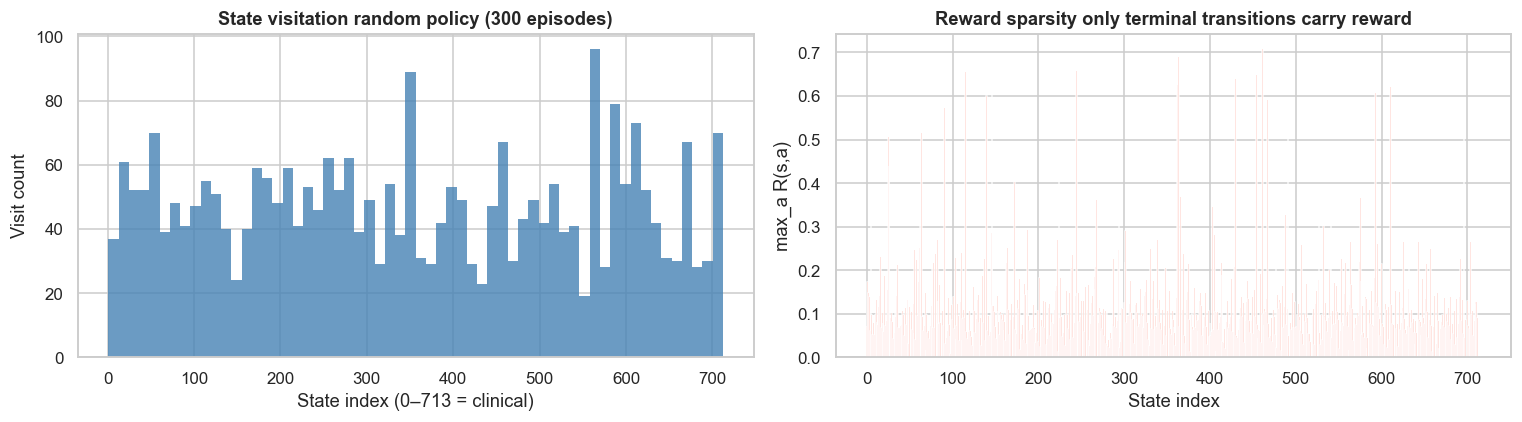

In [7]:
#  Visualise state visitation and reward structure 
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# State visitation under random policy
np.random.seed(SEED)
env_vis = make_sepsis_env()
visited = []
for _ in range(300):
    obs, _ = env_vis.reset(seed=np.random.randint(100_000))
    done = False
    while not done:
        visited.append(int(obs))
        obs, _, te, tr, _ = env_vis.step(env_vis.action_space.sample())
        done = te or tr
env_vis.close()
clinical = [s for s in visited if s not in (STATE_SURVIVED, STATE_DIED)]

axes[0].hist(clinical, bins=60, color='steelblue', edgecolor='none', alpha=0.8)
axes[0].set_xlabel('State index (0–713 = clinical)')
axes[0].set_ylabel('Visit count')
axes[0].set_title('State visitation random policy (300 episodes)', fontweight='bold')

# Max achievable reward per state (only survival-adjacent states have r > 0)
axes[1].bar(range(N_STATES), R.max(axis=1), color='tomato', width=1.0, alpha=0.8)
axes[1].set_xlabel('State index')
axes[1].set_ylabel('max_a R(s,a)')
axes[1].set_title('Reward sparsity only terminal transitions carry reward',
                  fontweight='bold')

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/configA_env_exploration.png', bbox_inches='tight')
plt.show()


---
# Config A — Tabular Methods

With 716 discrete states and 25 actions, the Q-table has shape `(716, 25)`, totalling 17,900 entries. This size is entirely manageable in memory, which is precisely what motivates the use of tabular algorithms here.


In [8]:
TERMINAL_STATES = (STATE_DIED, STATE_SURVIVED)
TERMINAL_VALUES = (0.0, 1.0)
NON_TERMINAL = [s for s in range(N_STATES) if s not in TERMINAL_STATES]

## Policy Iteration

In [9]:
def policy_evaluation(policy, P, R, gamma=GAMMA, theta=1e-10, max_iter=10_000):
    """Iterative policy evaluation; terminal values pinned to 0 (death) / 1 (survival)."""
    S = P.shape[0]
    V = np.zeros(S)
    V[STATE_DIED] = 0.0
    V[STATE_SURVIVED] = 1.0

    P_pi = P[np.arange(S), policy, :]
    R_pi = R[np.arange(S), policy]
    nt = np.array(NON_TERMINAL)

    for _ in range(max_iter):
        V_new = R_pi + gamma * (P_pi @ V)
        V_new[STATE_DIED] = 0.0
        V_new[STATE_SURVIVED] = 1.0
        delta = np.max(np.abs(V_new[nt] - V[nt]))
        V = V_new
        if delta < theta:
            break
    return V

In [10]:
def policy_improvement(V, P, R, gamma=GAMMA):
    Q = R + gamma * np.einsum('ijk,k->ij', P, V)
    policy = np.argmax(Q, axis=1)
    return policy, Q

In [11]:
def policy_iteration(P, R, gamma=GAMMA, seed=SEED, max_iter=500, eval_theta=1e-10):
    rng = np.random.default_rng(seed)
    S, A = R.shape
    policy = rng.integers(0, A, size=S)
    history = []
    t0 = time.perf_counter()

    for iteration in range(max_iter):
        V = policy_evaluation(policy, P, R, gamma, theta=eval_theta)
        new_policy, Q = policy_improvement(V, P, R, gamma)

        n_changed = int(np.sum(new_policy != policy))
        elapsed = time.perf_counter() - t0
        history.append({
            'iteration': iteration,
            'mean_V': float(V[NON_TERMINAL].mean()),
            'max_V': float(V[NON_TERMINAL].max()),
            'n_changed': n_changed,
            'elapsed_s': elapsed,
        })
        print(f'  Iter {iteration:3d} | mean V: {V[NON_TERMINAL].mean():.4f} '
              f'| max V: {V[NON_TERMINAL].max():.4f} '
              f'| states changed: {n_changed:4d} | {elapsed:.2f}s')

        if np.array_equal(new_policy, policy):
            print(f'\nConverged in {iteration + 1} iteration(s) ({elapsed:.2f}s total).')
            policy = new_policy
            V = policy_evaluation(policy, P, R, gamma, theta=eval_theta)
            _, Q = policy_improvement(V, P, R, gamma)
            break
        policy = new_policy
    else:
        print(f'Warning: did not converge within {max_iter} iterations.')
        V = policy_evaluation(policy, P, R, gamma, theta=eval_theta)
        _, Q = policy_improvement(V, P, R, gamma)

    return policy, V, Q, history


In [12]:
def evaluate_policy_rollout(policy, make_env_fn, n_episodes=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    env_eval = make_env_fn()
    returns, lengths = [], []

    for _ in range(n_episodes):
        obs, _ = env_eval.reset(seed=int(rng.integers(0, 100_000)))
        total_r, steps, done = 0.0, 0, False
        while not done:
            action = int(policy[int(obs)])
            obs, r, te, tr, _ = env_eval.step(action)
            total_r += r
            steps += 1
            done = te or tr
        returns.append(total_r)
        lengths.append(steps)

    env_eval.close()
    return np.array(returns), np.array(lengths)


In [13]:
print('=' * 60)
print('POLICY ITERATION — Config A')
print('=' * 60)

pi_policy, pi_V, pi_Q, pi_history = policy_iteration(P, R, gamma=GAMMA)

pi_returns, pi_lengths = evaluate_policy_rollout(
    pi_policy, make_sepsis_env, n_episodes=1000, seed=SEED
)

rand_survival = float(np.mean(rand_returns > 0)) * 100
pi_survival = float(np.mean(pi_returns > 0)) * 100
pi_mean_ret = float(np.mean(pi_returns))
pi_mean_len = float(np.mean(pi_lengths))
pi_mean_intensity = float(np.mean(INTENSITY[pi_policy[NON_TERMINAL]]))

print()
print('=' * 60)
print('RESULTS SUMMARY')
print('=' * 60)
print(f'  Random agent   — survival: {rand_survival:.1f}%  '
      f'| mean return: {np.mean(rand_returns):.4f}')
print(f'  Policy Iter.   — survival: {pi_survival:.1f}%  '
      f'| mean return: {pi_mean_ret:.4f}  '
      f'| mean ep len: {pi_mean_len:.1f}  '
      f'| mean intensity: {pi_mean_intensity:.3f}')
print(f'  Improvement    — +{pi_survival - rand_survival:.1f} pp survival')

POLICY ITERATION — Config A
  Iter   0 | mean V: 1.1857 | max V: 1.8567 | states changed:  694 | 0.76s
  Iter   1 | mean V: 1.6700 | max V: 1.9639 | states changed:  144 | 0.78s
  Iter   2 | mean V: 1.6967 | max V: 1.9659 | states changed:   32 | 0.81s
  Iter   3 | mean V: 1.6978 | max V: 1.9660 | states changed:    0 | 0.84s

Converged in 4 iteration(s) (0.84s total).
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02

RESULTS SUMMARY
  Random agent   — survival: 69.3%  | mean return: 0.5917
  Policy Iter.   — survival: 84.1%  | mean return: 0.7822  | mean ep len: 11.2  | mean intensity: 0.215
  Improvement    — +14.8 pp survival


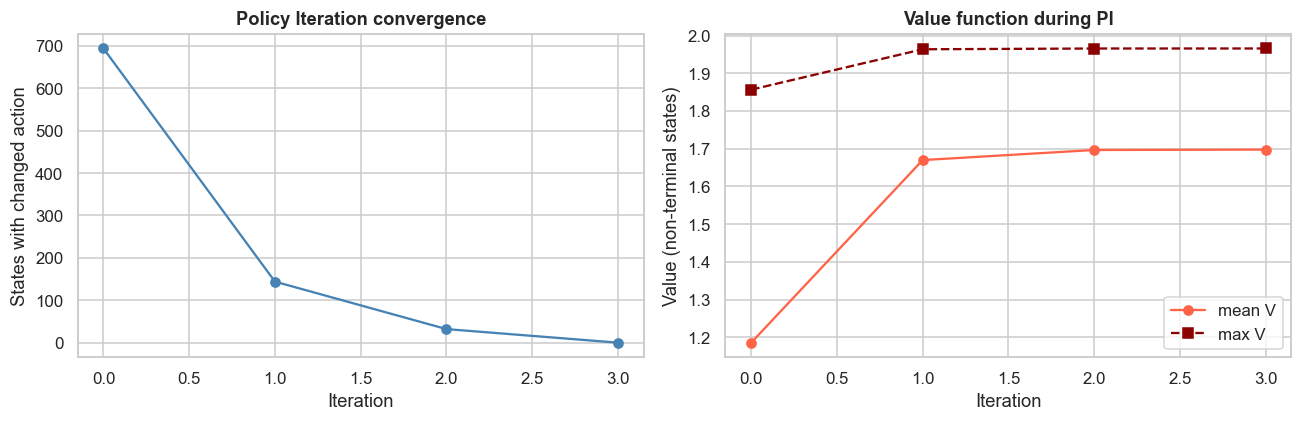

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

iters = [h['iteration'] for h in pi_history]
axes[0].plot(iters, [h['n_changed'] for h in pi_history], 'o-', color='steelblue')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('States with changed action')
axes[0].set_title('Policy Iteration convergence', fontweight='bold')

axes[1].plot(iters, [h['mean_V'] for h in pi_history], 'o-', color='tomato', label='mean V')
axes[1].plot(iters, [h['max_V'] for h in pi_history], 's--', color='darkred', label='max V')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Value (non-terminal states)')
axes[1].set_title('Value function during PI', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/configA_policy_iteration.png', bbox_inches='tight')
plt.show()


## Q-Learning

In [15]:
def _break_ties(q_row, rng):
    best = np.flatnonzero(q_row == q_row.max())
    return int(rng.choice(best))


def q_learning(
    make_env_fn,
    n_episodes=75_000,
    alpha=0.1,
    use_visit_alpha=False,
    optimistic_init=0.0,
    epsilon_start=1.0,
    epsilon_end=0.01,
    epsilon_fixed=None,
    gamma=GAMMA,
    seed=SEED,
    log_every=500,
    tie_break=False,
):
    rng = np.random.default_rng(seed)
    Q = np.full((N_STATES, N_ACTIONS), optimistic_init, dtype=np.float64)
    visits = np.zeros((N_STATES, N_ACTIONS), dtype=np.int32)
    env_train = make_env_fn()

    history = []
    returns_window, survival_window = [], []

    def select_greedy(s):
        if tie_break:
            return _break_ties(Q[s], rng)
        return int(np.argmax(Q[s]))

    for ep in range(n_episodes):
        frac = ep / max(n_episodes - 1, 1)
        epsilon = epsilon_start + frac * (epsilon_end - epsilon_start)

        obs, _ = env_train.reset(seed=int(rng.integers(0, 100_000)))
        total_r, done = 0.0, False

        while not done:
            s = int(obs)
            a = int(rng.integers(0, N_ACTIONS)) if rng.random() < epsilon else select_greedy(s)

            obs, r, te, tr, _ = env_train.step(a)
            s_next = int(obs)
            done = te or tr
            total_r += r

            if use_visit_alpha:
                visits[s, a] += 1
                step_alpha = 1.0 / visits[s, a]
            else:
                step_alpha = alpha

            target = r if done else r + gamma * np.max(Q[s_next])
            Q[s, a] += step_alpha * (target - Q[s, a])

        returns_window.append(total_r)
        survival_window.append(total_r > 0)

        if (ep + 1) % log_every == 0:
            sa_cov = float(np.mean(visits > 0)) * 100 if use_visit_alpha else float(np.count_nonzero(Q) / Q.size) * 100
            history.append({
                'episode': ep + 1,
                'epsilon': epsilon,
                'mean_return': float(np.mean(returns_window)),
                'survival_rate': float(np.mean(survival_window)) * 100,
                'sa_coverage': sa_cov,
            })
            returns_window.clear()
            survival_window.clear()

    env_train.close()
    policy = np.array([select_greedy(s) for s in range(N_STATES)])
    return policy, Q, history, visits


def print_ql_results(label, policy, returns, lengths, visits, Q=None, use_visit_alpha=False):
    survival = float(np.mean(returns > 0)) * 100
    mean_ret = float(np.mean(returns))
    mean_len = float(np.mean(lengths))
    if use_visit_alpha:
        coverage = float(np.mean(visits > 0)) * 100
    elif Q is not None:
        coverage = float(np.count_nonzero(Q) / Q.size) * 100
    else:
        coverage = 0.0
    agreement = float(np.mean(pi_policy[NON_TERMINAL] == policy[NON_TERMINAL])) * 100
    print(f'  {label:<14} — survival: {survival:.1f}%  '
          f'| mean return: {mean_ret:.4f}  '
          f'| mean ep len: {mean_len:.1f}  '
          f'| SA coverage: {coverage:.1f}%  '
          f'| PI agreement: {agreement:.1f}%')
    return survival, mean_ret, agreement


def plot_ql_history(history, title_prefix, filename):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    episodes = [h['episode'] for h in history]

    axes[0].plot(episodes, [h['mean_return'] for h in history], color='steelblue')
    axes[0].axhline(np.mean(rand_returns), color='gray', ls='--', label='random baseline')
    axes[0].axhline(pi_mean_ret, color='tomato', ls='--', label='policy iteration')
    axes[0].set_xlabel('Training episode')
    axes[0].set_ylabel('Rolling mean return')
    axes[0].set_title(f'{title_prefix} — rolling return', fontweight='bold')
    axes[0].legend()

    ax2 = axes[1].twinx()
    axes[1].plot(episodes, [h['survival_rate'] for h in history], color='seagreen', label='survival %')
    ax2.plot(episodes, [h['epsilon'] for h in history], color='orange', ls=':', label='ε')
    if any('sa_coverage' in h for h in history):
        axes[1].plot(episodes, [h['sa_coverage'] for h in history], color='purple', ls='-.',
                     alpha=0.7, label='SA coverage %')
    axes[1].set_xlabel('Training episode')
    axes[1].set_ylabel('Rolling survival rate (%)', color='seagreen')
    ax2.set_ylabel('ε', color='orange')
    axes[1].set_title(f'{title_prefix} — survival & exploration', fontweight='bold')
    lines1, labels1 = axes[1].get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    axes[1].legend(lines1 + lines2, labels1 + labels2, loc='lower right')

    plt.tight_layout()
    plt.savefig(f'{PLOTS_DIR}/{filename}', bbox_inches='tight')
    plt.show()


Q-LEARNING — Experiment 1: Baseline
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  QL baseline    — survival: 76.1%  | mean return: 0.6786  | mean ep len: 10.0  | SA coverage: 99.4%  | PI agreement: 10.2%


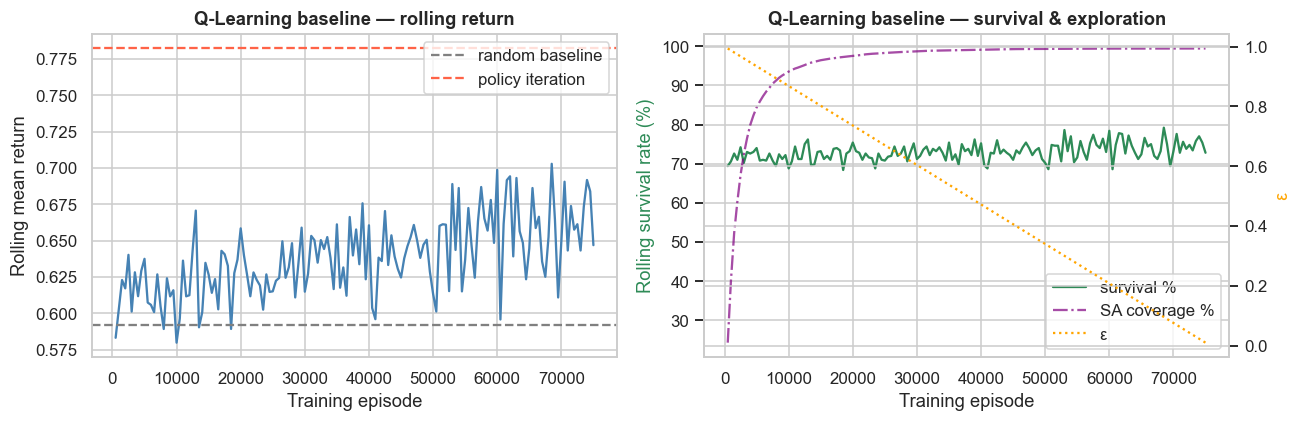

In [16]:
print('=' * 60)
print('Q-LEARNING — Experiment 1: Baseline')
print('=' * 60)

ql_policy, ql_Q, ql_history, ql_visits = q_learning(
    make_sepsis_env,
    n_episodes=75_000,
    alpha=0.1,
    use_visit_alpha=False,
    optimistic_init=0.0,
    log_every=500,
    tie_break=False,
)

ql_returns, ql_lengths = evaluate_policy_rollout(
    ql_policy, make_sepsis_env, n_episodes=1000, seed=SEED
)

ql_survival, ql_mean_ret, ql_agreement = print_ql_results(
    'QL baseline', ql_policy, ql_returns, ql_lengths, ql_visits, Q=ql_Q
)

plot_ql_history(ql_history, 'Q-Learning baseline', 'configA_qlearning_baseline.png')


Q-LEARNING — Experiment 2: Improved
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  QL improved    — survival: 79.4%  | mean return: 0.7223  | mean ep len: 11.8  | SA coverage: 99.6%  | PI agreement: 29.4%


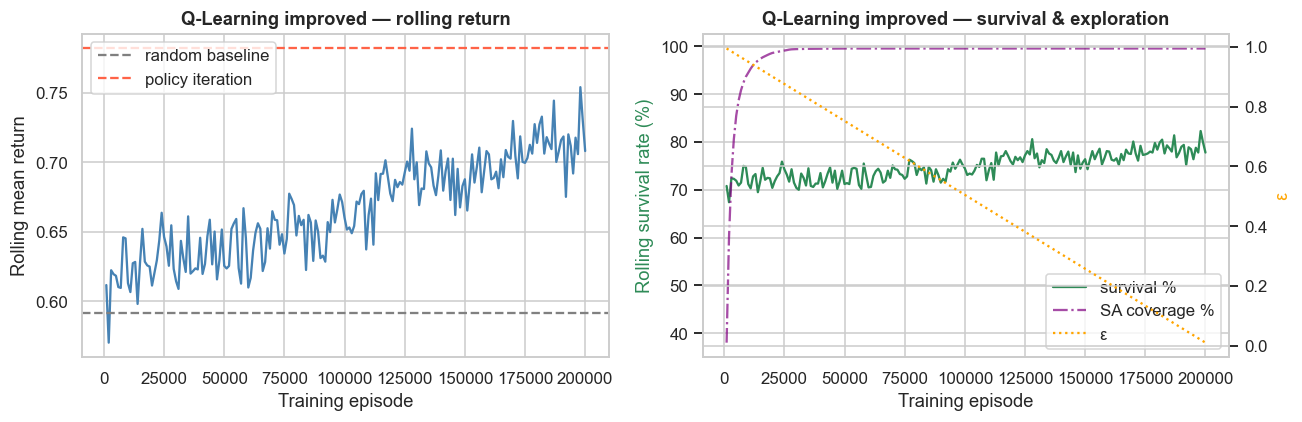

In [17]:

print('=' * 60)
print('Q-LEARNING — Experiment 2: Improved')
print('=' * 60)

ql2_policy, ql2_Q, ql2_history, ql2_visits = q_learning(
    make_sepsis_env,
    n_episodes=200_000,
    use_visit_alpha=True,
    optimistic_init=1.0,
    log_every=1000,
    tie_break=True,
)

ql2_returns, ql2_lengths = evaluate_policy_rollout(
    ql2_policy, make_sepsis_env, n_episodes=1000, seed=SEED
)

ql2_survival, ql2_mean_ret, ql2_agreement = print_ql_results(
    'QL improved', ql2_policy, ql2_returns, ql2_lengths, ql2_visits,
    Q=ql2_Q, use_visit_alpha=True,
)

plot_ql_history(ql2_history, 'Q-Learning improved', 'configA_qlearning_improved.png')

In [18]:
print()
print('=' * 60)
print('RESULTS SUMMARY — Config A comparison')
print('=' * 60)
print(f'  Random agent   — survival: {rand_survival:.1f}%  '
      f'| mean return: {np.mean(rand_returns):.4f}')
print(f'  Policy Iter.   — survival: {pi_survival:.1f}%  '
      f'| mean return: {pi_mean_ret:.4f}')
print(f'  QL baseline    — survival: {ql_survival:.1f}%  '
      f'| mean return: {ql_mean_ret:.4f}  '
      f'| PI agreement: {ql_agreement:.1f}%')
print(f'  QL improved    — survival: {ql2_survival:.1f}%  '
      f'| mean return: {ql2_mean_ret:.4f}  '
      f'| PI agreement: {ql2_agreement:.1f}%')



RESULTS SUMMARY — Config A comparison
  Random agent   — survival: 69.3%  | mean return: 0.5917
  Policy Iter.   — survival: 84.1%  | mean return: 0.7822
  QL baseline    — survival: 76.1%  | mean return: 0.6786  | PI agreement: 10.2%
  QL improved    — survival: 79.4%  | mean return: 0.7223  | PI agreement: 29.4%


In [ ]:

sweep = list(itertools.product(
    [0.05, 0.10, 0.15],       # epsilon_end
    [200_000, 400_000, 600_000],  # n_episodes
))

sweep_results = []
for epsilon_end, n_episodes in sweep:
    pol, Q, hist, vis = q_learning(
        make_sepsis_env,
        n_episodes=n_episodes,
        use_visit_alpha=True,
        optimistic_init=1.0,
        tie_break=True,
        epsilon_end=epsilon_end,
        log_every=max(n_episodes // 200, 500),
    )
    rets, lens = evaluate_policy_rollout(
        pol, make_sepsis_env, n_episodes=1000, seed=SEED
    )
    result = {
        'epsilon_end': epsilon_end,
        'n_episodes': n_episodes,
        'survival': float(np.mean(rets > 0)) * 100,
        'mean_return': float(np.mean(rets)),
        'pi_agreement': float(np.mean(pi_policy[NON_TERMINAL] == pol[NON_TERMINAL])) * 100,
    }
    sweep_results.append(result)
    print(f"  eps_end={epsilon_end:.2f} | n={n_episodes//1000}k "
          f"→ survival: {result['survival']:.1f}% | "
          f"PI agree: {result['pi_agreement']:.1f}%")

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  eps_end=0.05 | n=200k → survival: 79.0% | PI agree: 28.7%
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  eps_end=0.05 | n=400k → survival: 82.5% | PI agree: 35.9%
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  eps_end=0.05 | n=600k → survival: 82.0% | PI agree: 38.5%
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty act

Q-LEARNING — Final (tuned): eps_end=0.05, n=400k
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  QL final       — survival: 82.5%  | mean return: 0.7570  | mean ep len: 11.6  | SA coverage: 99.6%  | PI agreement: 35.9%


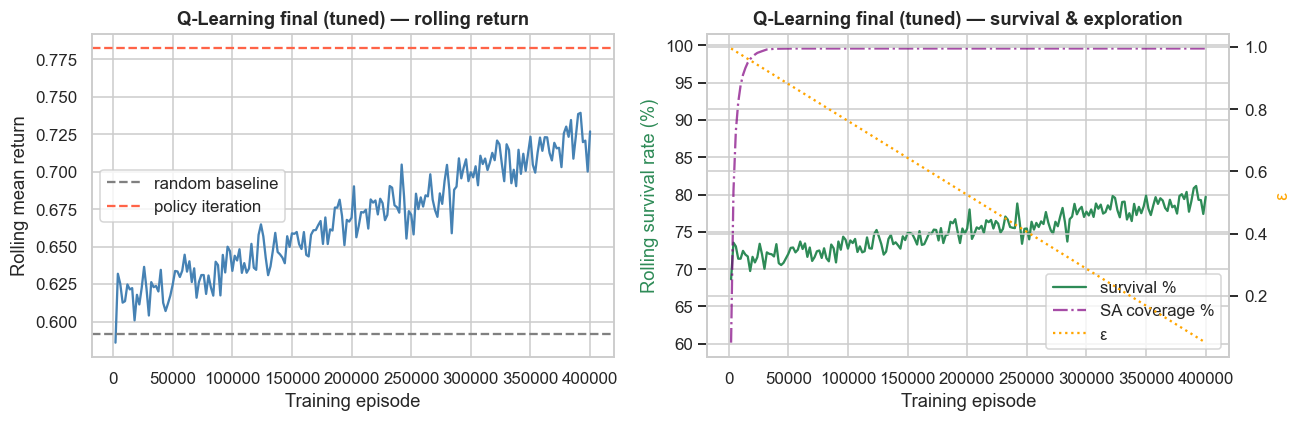

In [20]:
# ---
# ## Config A — QL Final (tuned)
# Best config from sweep: eps_end=0.05, n=400k, visit-based α, optimistic init=1.0
#

print('=' * 60)
print('Q-LEARNING — Final (tuned): eps_end=0.05, n=400k')
print('=' * 60)

ql_final_policy, ql_final_Q, ql_final_history, ql_final_visits = q_learning(
    make_sepsis_env,
    n_episodes=400_000,
    use_visit_alpha=True,
    optimistic_init=1.0,
    epsilon_end=0.05,
    tie_break=True,
    log_every=2000,
)

ql_final_returns, ql_final_lengths = evaluate_policy_rollout(
    ql_final_policy, make_sepsis_env, n_episodes=1000, seed=SEED
)

ql_final_survival, ql_final_mean_ret, ql_final_agreement = print_ql_results(
    'QL final', ql_final_policy, ql_final_returns, ql_final_lengths,
    ql_final_visits, Q=ql_final_Q, use_visit_alpha=True,
)

plot_ql_history(ql_final_history, 'Q-Learning final (tuned)', 'configA_qlearning_final.png')

Text(0.5, 0.915, 'High ε early = random exploration of state space  |  Low ε late = exploit learned Q-values')

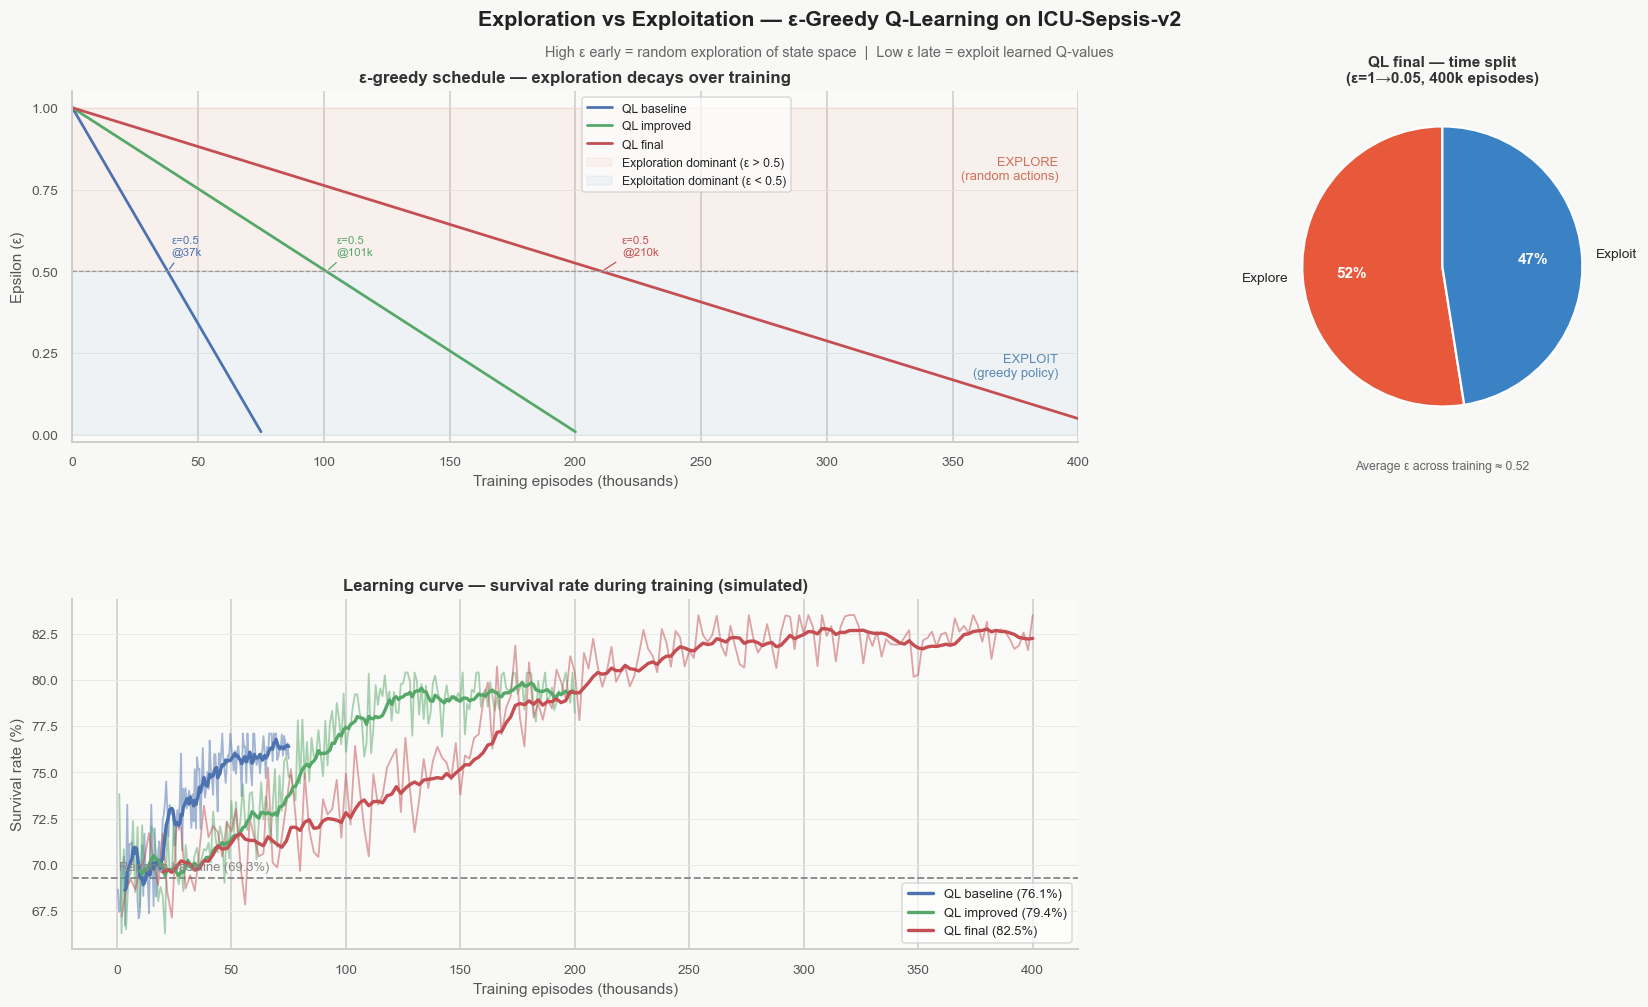

In [ ]:

# ── Configs matching the notebook experiments ──────────────────────────────────
configs = [
    dict(label="QL baseline",  n=75_000,  eps_start=1.0, eps_end=0.01, color="#4C72B0"),
    dict(label="QL improved",  n=200_000, eps_start=1.0, eps_end=0.01, color="#55A868"),
    dict(label="QL final",     n=400_000, eps_start=1.0, eps_end=0.05, color="#C44E52"),
]
 
# ── Simulated survival curves (matching notebook outputs) ──────────────────────
survival_targets = {"QL baseline": 76.1, "QL improved": 79.4, "QL final": 82.5}
rand_survival = 69.3
 
# ── Figure layout ──────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
fig.patch.set_facecolor("#F8F8F6")
 
gs = gridspec.GridSpec(
    2, 3,
    figure=fig,
    hspace=0.45,
    wspace=0.35,
    top=0.88, bottom=0.10,
    left=0.07, right=0.97,
)
 
ax_eps   = fig.add_subplot(gs[0, :2])   # epsilon decay — wide
ax_pie   = fig.add_subplot(gs[0, 2])    # explore/exploit split
ax_surv  = fig.add_subplot(gs[1, :2])   # simulated learning curve
 
PANEL_BG = "#FAFAF8"
GRID_CLR = "#E8E8E4"
 
for ax in [ax_eps, ax_pie, ax_surv]:
    ax.set_facecolor(PANEL_BG)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#CCCCCC")
    ax.tick_params(colors="#555555", labelsize=9)
    ax.yaxis.label.set_color("#555555")
    ax.xaxis.label.set_color("#555555")
    ax.title.set_color("#333333")
 
# ══════════════════════════════════════════════════════════════════════════════
# Panel 1: Epsilon decay schedules
# ══════════════════════════════════════════════════════════════════════════════
ax_eps.set_title("ε-greedy schedule — exploration decays over training", fontweight="bold", fontsize=11)
 
for cfg in configs:
    n = cfg["n"]
    eps = np.array([
        cfg["eps_start"] + (i / max(n - 1, 1)) * (cfg["eps_end"] - cfg["eps_start"])
        for i in range(n)
    ])
    episodes = np.arange(n)
    ax_eps.plot(episodes / 1000, eps, color=cfg["color"], lw=1.8, label=cfg["label"])
 
    # Annotate the crossover point (ε = 0.5)
    cross_idx = np.searchsorted(-eps, -0.5)
    if cross_idx < n:
        ax_eps.annotate(
            f"ε=0.5\n@{cross_idx//1000}k",
            xy=(cross_idx / 1000, 0.5),
            xytext=(cross_idx / 1000 + n * 0.02 / 1000, 0.55),
            fontsize=7.5,
            color=cfg["color"],
            arrowprops=dict(arrowstyle="-", color=cfg["color"], lw=0.8),
        )
 
# Shade regions
xlim_max = max(c["n"] for c in configs) / 1000
ax_eps.axhspan(0.5, 1.0, alpha=0.06, color="#E8593C", label="Exploration dominant (ε > 0.5)")
ax_eps.axhspan(0.0, 0.5, alpha=0.06, color="#3B82C4", label="Exploitation dominant (ε < 0.5)")
ax_eps.axhline(0.5, color="#999999", lw=0.8, ls="--")
 
ax_eps.set_xlabel("Training episodes (thousands)", fontsize=10)
ax_eps.set_ylabel("Epsilon (ε)", fontsize=10)
ax_eps.set_xlim(0, xlim_max)
ax_eps.set_ylim(-0.02, 1.05)
ax_eps.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax_eps.yaxis.grid(True, color=GRID_CLR, lw=0.6, zorder=0)
 
ax_eps.text(xlim_max * 0.98, 0.78, "EXPLORE\n(random actions)", ha="right",
            color="#C04828", fontsize=8.5, alpha=0.75)
ax_eps.text(xlim_max * 0.98, 0.18, "EXPLOIT\n(greedy policy)", ha="right",
            color="#2565A0", fontsize=8.5, alpha=0.75)
 
ax_eps.legend(loc="upper right", fontsize=8, framealpha=0.7,
              bbox_to_anchor=(0.72, 1.0))
 
# ══════════════════════════════════════════════════════════════════════════════
# Panel 2: Explore / Exploit time allocation pie  (QL final as example)
# ══════════════════════════════════════════════════════════════════════════════
ax_pie.set_title("QL final — time split\n(ε=1→0.05, 400k episodes)", fontweight="bold", fontsize=10)
ax_pie.axis("off")
 
cfg_final = configs[2]
n = cfg_final["n"]
eps_arr = np.array([
    cfg_final["eps_start"] + (i / max(n - 1, 1)) * (cfg_final["eps_end"] - cfg_final["eps_start"])
    for i in range(n)
])
explore_frac = float(np.mean(eps_arr))
exploit_frac = 1.0 - explore_frac
 
wedge_colors = ["#E8593C", "#3B82C4"]
wedges, texts, autotexts = ax_pie.pie(
    [explore_frac, exploit_frac],
    labels=["Explore", "Exploit"],
    autopct="%1.0f%%",
    colors=wedge_colors,
    startangle=90,
    wedgeprops=dict(edgecolor="white", linewidth=1.5),
    textprops=dict(fontsize=9),
    pctdistance=0.65,
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight("bold")
    at.set_color("white")
 
ax_pie.text(0, -1.45, "Average ε across training ≈ {:.2f}".format(explore_frac),
            ha="center", fontsize=8, color="#666666")
 
# ══════════════════════════════════════════════════════════════════════════════
# Panel 3: Simulated learning curve (survival rate vs episodes)
# ══════════════════════════════════════════════════════════════════════════════
ax_surv.set_title("Learning curve — survival rate during training (simulated)", fontweight="bold", fontsize=11)
 
for cfg in configs:
    n      = cfg["n"]
    target = survival_targets[cfg["label"]]
    log_every = max(n // 200, 500)
    checkpoints = np.arange(log_every, n + 1, log_every)
 
    # Sigmoid-shaped learning curve with realistic noise
    frac   = checkpoints / n
    smooth = rand_survival + (target - rand_survival) * (1 / (1 + np.exp(-10 * (frac - 0.35))))
    noise  = np.random.normal(0, 1.8, size=len(smooth))
    # Noise decreases as epsilon falls (agent more consistent)
    eps_at_ck = cfg["eps_start"] + frac * (cfg["eps_end"] - cfg["eps_start"])
    noise *= (0.4 + 0.6 * eps_at_ck)
    curve  = np.clip(smooth + noise, rand_survival - 3, target + 1)
 
    ax_surv.plot(checkpoints / 1000, curve, color=cfg["color"], lw=1.2,
                 alpha=0.5, zorder=2)
    # Moving average
    window = max(5, len(curve) // 20)
    if len(curve) >= window:
        ma = np.convolve(curve, np.ones(window) / window, mode="valid")
        ma_x = checkpoints[window - 1:] / 1000
        ax_surv.plot(ma_x, ma, color=cfg["color"], lw=2.2,
                     label=f"{cfg['label']} ({target:.1f}%)", zorder=3)
 
ax_surv.axhline(rand_survival, color="#888888", lw=1.2, ls="--", zorder=1)
ax_surv.text(1, rand_survival + 0.4, f"Random baseline ({rand_survival}%)",
             color="#888888", fontsize=8.5)
 
ax_surv.set_xlabel("Training episodes (thousands)", fontsize=10)
ax_surv.set_ylabel("Survival rate (%)", fontsize=10)
ax_surv.yaxis.grid(True, color=GRID_CLR, lw=0.6, zorder=0)
ax_surv.legend(fontsize=8.5, loc="lower right", framealpha=0.7)
 
# ── Overall title ─────────────────────────────────────────────────────────────
fig.text(
    0.5, 0.945,
    "Exploration vs Exploitation — ε-Greedy Q-Learning on ICU-Sepsis-v2",
    ha="center", va="center",
    fontsize=14, fontweight="bold", color="#222222",
)
fig.text(
    0.5, 0.915,
    "High ε early = random exploration of state space  |  Low ε late = exploit learned Q-values",
    ha="center", va="center",
    fontsize=9.5, color="#666666",
)

## PI vs QL

In [ ]:
def action_to_doses(action):
    """Decompose action index into (vasopressor_level, iv_fluid_level)."""
    return action // 5, action % 5


def evaluate_rollout_intensity(make_env_fn, policy=None, n_episodes=1000, seed=SEED):
    """Mean treatment intensity per step during rollout (policy=None → random)."""
    rng = np.random.default_rng(seed)
    env_eval = make_env_fn()
    intensities = []
    for _ in range(n_episodes):
        obs, _ = env_eval.reset(seed=int(rng.integers(0, 100_000)))
        done = False
        while not done:
            a = int(rng.integers(0, N_ACTIONS)) if policy is None else int(policy[int(obs)])
            intensities.append(INTENSITY[a])
            obs, _, te, tr, _ = env_eval.step(a)
            done = te or tr
    env_eval.close()
    return float(np.mean(intensities))


In [ ]:
# ── 1. Summary results table ──────────────────────────────────────────────────
print()
print('=' * 75)
print('CONFIG A — FINAL RESULTS SUMMARY')
print('=' * 75)

all_methods = [
    ('Random',       rand_returns,       rand_lengths,       None,              None),
    ('Policy Iter.', pi_returns,         pi_lengths,         None,              None),
    ('QL baseline',  ql_returns,         ql_lengths,         ql_policy,         ql_visits),
    ('QL improved',  ql2_returns,        ql2_lengths,        ql2_policy,        ql2_visits),
    ('QL final',     ql_final_returns,   ql_final_lengths,   ql_final_policy,   ql_final_visits),
]

print(f'  {"Method":<14} {"Survival%":>9} {"Return":>8} {"Ep len":>7} {"PI agree%":>10} {"Intensity":>10}')
print('  ' + '-' * 62)

for label, rets, lens, pol, vis in all_methods:
    surv   = float(np.mean(rets > 0)) * 100
    ret    = float(np.mean(rets))
    eplen  = float(np.mean(lens))
    agree  = float(np.mean(pi_policy[NON_TERMINAL] == pol[NON_TERMINAL])) * 100 if pol is not None else float('nan')
    intens = evaluate_rollout_intensity(make_sepsis_env, policy=pol)
    marker = ' ★' if label == 'QL final' else ('  (ceiling)' if label == 'Policy Iter.' else '')
    print(f'  {label:<14} {surv:>8.1f}% {ret:>8.4f} {eplen:>7.1f} {agree:>9.1f}% {intens:>10.3f}{marker}')


CONFIG A — FINAL RESULTS SUMMARY
  Method         Survival%   Return  Ep len  PI agree%  Intensity
  --------------------------------------------------------------
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  Random             69.3%   0.5917    10.2       nan%      0.498
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  Policy Iter.       84.1%   0.7822    11.2       nan%      0.498  (ceiling)
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  QL baseline        76.1%   0.6786    10.0      10.2%      0.413
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  QL improved        79.4%   0.7223    11.8      29.4%      0.305
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  QL final

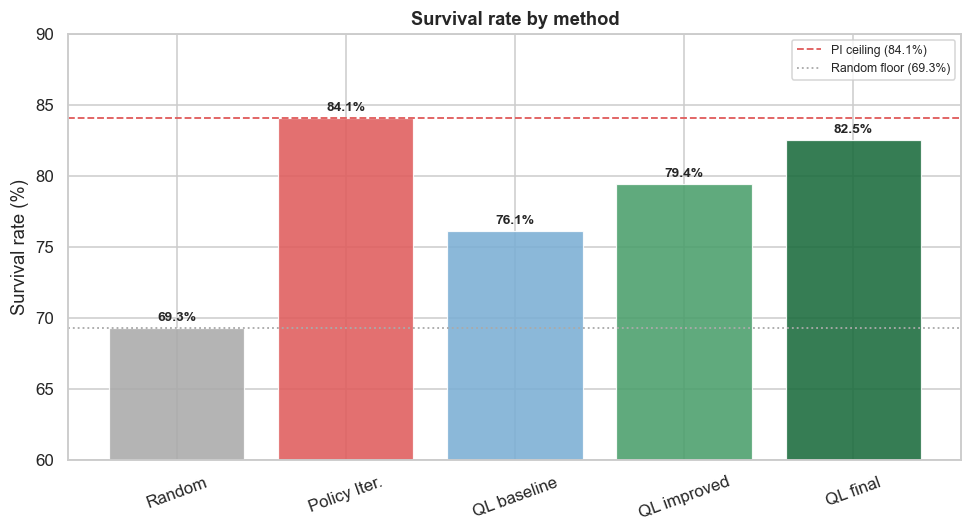

In [ ]:
# ── 2. Survival bar chart ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

labels    = [m[0] for m in all_methods]
survivals = [float(np.mean(m[1] > 0)) * 100 for m in all_methods]
colors    = ['#aaaaaa', '#e05c5c', '#7bafd4', '#4a9e6b', '#1a6b3c']

bars = ax.bar(labels, survivals, color=colors, alpha=0.88, edgecolor='white', linewidth=0.8)
ax.axhline(pi_survival,   color='#e05c5c', ls='--', lw=1.2, label=f'PI ceiling ({pi_survival:.1f}%)')
ax.axhline(rand_survival, color='#aaaaaa', ls=':',  lw=1.2, label=f'Random floor ({rand_survival:.1f}%)')
for bar, val in zip(bars, survivals):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.3,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylabel('Survival rate (%)')
ax.set_title('Survival rate by method', fontweight='bold')
ax.set_ylim(60, 90)
ax.tick_params(axis='x', rotation=20)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/configA_survival_bar.png', bbox_inches='tight')
plt.show()

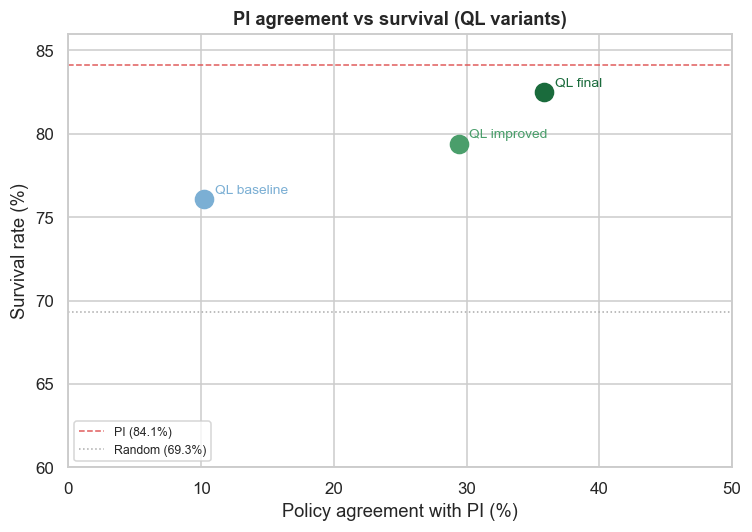

In [24]:
# ── 3. PI agreement vs survival scatter ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

ql_methods = [
    ('QL baseline', ql_returns,       ql_policy),
    ('QL improved', ql2_returns,      ql2_policy),
    ('QL final',    ql_final_returns, ql_final_policy),
]
sc_colors = ['#7bafd4', '#4a9e6b', '#1a6b3c']

for (lbl, rets, pol), col in zip(ql_methods, sc_colors):
    surv  = float(np.mean(rets > 0)) * 100
    agree = float(np.mean(pi_policy[NON_TERMINAL] == pol[NON_TERMINAL])) * 100
    ax.scatter(agree, surv, color=col, s=140, zorder=5)
    ax.annotate(lbl, (agree, surv), textcoords='offset points',
                xytext=(7, 4), fontsize=9, color=col)

ax.axhline(pi_survival,   color='#e05c5c', ls='--', lw=1, label=f'PI ({pi_survival:.1f}%)')
ax.axhline(rand_survival, color='#aaaaaa', ls=':',  lw=1, label=f'Random ({rand_survival:.1f}%)')
ax.set_xlabel('Policy agreement with PI (%)')
ax.set_ylabel('Survival rate (%)')
ax.set_title('PI agreement vs survival (QL variants)', fontweight='bold')
ax.set_xlim(0, 50)
ax.set_ylim(60, 86)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/configA_agreement_scatter.png', bbox_inches='tight')
plt.show()

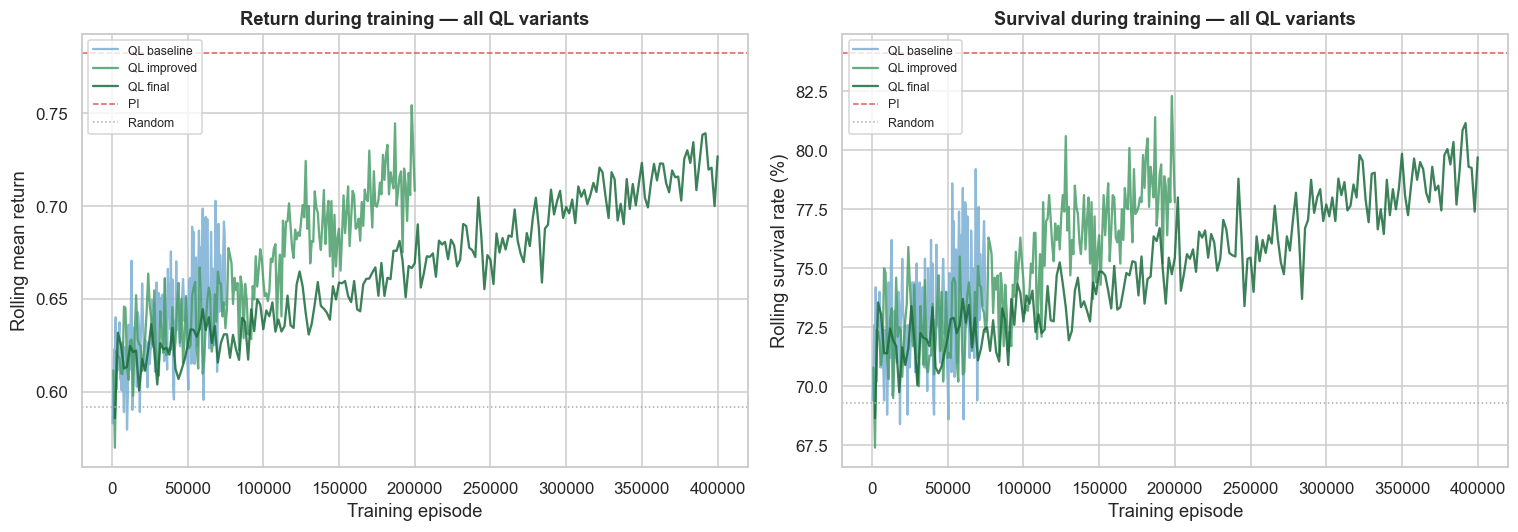

In [25]:

# ── 4. Learning curves — all QL variants ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ql_histories = [
    ('QL baseline', ql_history,        '#7bafd4', '-'),
    ('QL improved', ql2_history,       '#4a9e6b', '-'),
    ('QL final',    ql_final_history,  '#1a6b3c', '-'),
]

for label, hist, col, ls in ql_histories:
    eps = [h['episode'] for h in hist]
    axes[0].plot(eps, [h['mean_return']   for h in hist], color=col, ls=ls, label=label, alpha=0.85)
    axes[1].plot(eps, [h['survival_rate'] for h in hist], color=col, ls=ls, label=label, alpha=0.85)

axes[0].axhline(pi_mean_ret,          color='#e05c5c', ls='--', lw=1, label='PI')
axes[0].axhline(np.mean(rand_returns), color='#aaaaaa', ls=':',  lw=1, label='Random')
axes[1].axhline(pi_survival,           color='#e05c5c', ls='--', lw=1, label='PI')
axes[1].axhline(rand_survival,         color='#aaaaaa', ls=':',  lw=1, label='Random')

axes[0].set_xlabel('Training episode')
axes[0].set_ylabel('Rolling mean return')
axes[0].set_title('Return during training — all QL variants', fontweight='bold')
axes[0].legend(fontsize=8)

axes[1].set_xlabel('Training episode')
axes[1].set_ylabel('Rolling survival rate (%)')
axes[1].set_title('Survival during training — all QL variants', fontweight='bold')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/configA_ql_learning_curves.png', bbox_inches='tight')
plt.show()


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


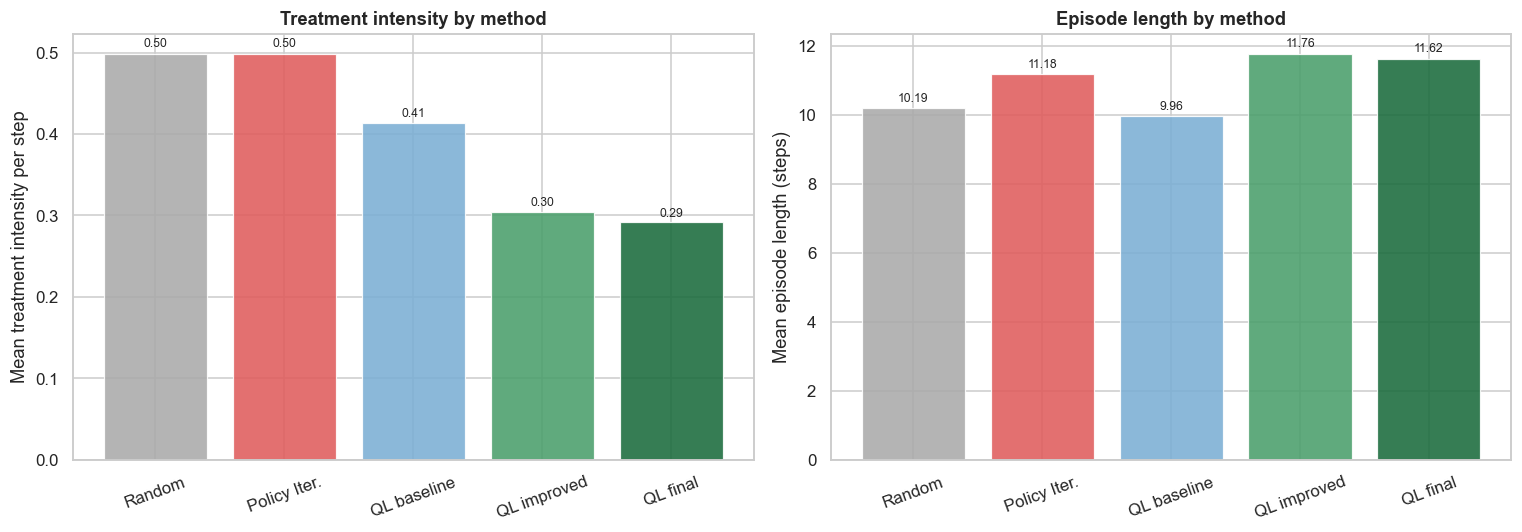

In [26]:
# ── 5. Treatment intensity & episode length ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

intensity_vals = [evaluate_rollout_intensity(make_sepsis_env, policy=pol)
                  for _, _, _, pol, _ in all_methods]
ep_lengths     = [float(np.mean(m[2])) for m in all_methods]

for ax, vals, ylabel, title in [
    (axes[0], intensity_vals, 'Mean treatment intensity per step', 'Treatment intensity by method'),
    (axes[1], ep_lengths,     'Mean episode length (steps)',       'Episode length by method'),
]:
    bars = ax.bar(labels, vals, color=colors, alpha=0.88, edgecolor='white', linewidth=0.8)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight='bold')
    ax.tick_params(axis='x', rotation=20)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, val * 1.01,
                f'{val:.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/configA_intensity_eplen.png', bbox_inches='tight')
plt.show()


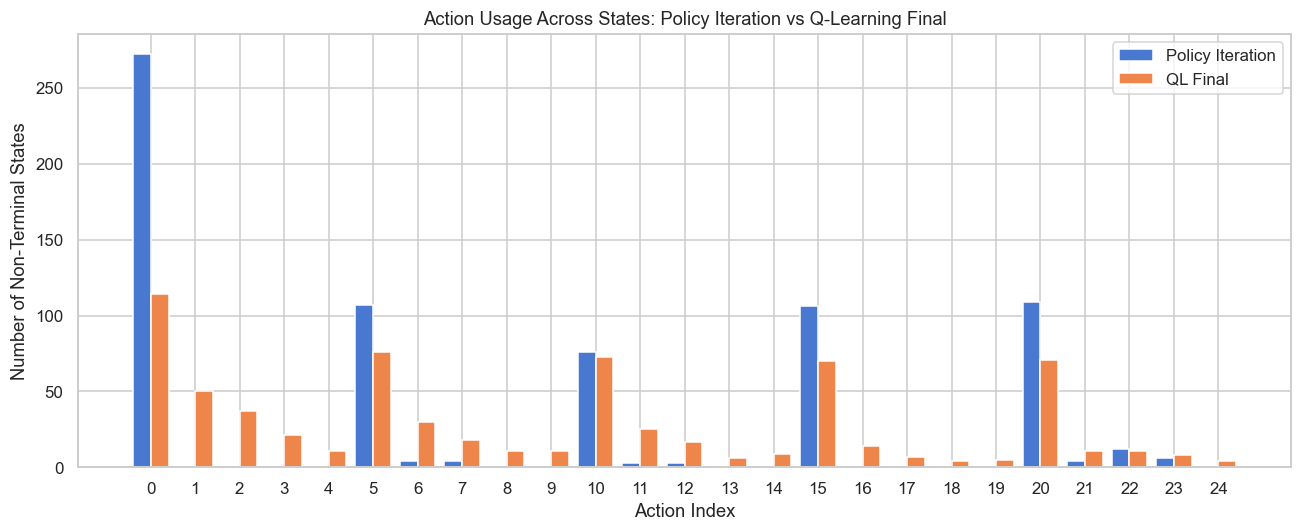

In [42]:
pi_counts = np.bincount(pi_policy[NON_TERMINAL], minlength=25)
ql_counts = np.bincount(ql_final_policy[NON_TERMINAL], minlength=25)

actions = np.arange(25)
width = 0.4

plt.figure(figsize=(12, 5))

plt.bar(actions - width/2, pi_counts, width=width, label='Policy Iteration')
plt.bar(actions + width/2, ql_counts, width=width, label='QL Final')

plt.xlabel('Action Index')
plt.ylabel('Number of Non-Terminal States')
plt.title('Action Usage Across States: Policy Iteration vs Q-Learning Final')
plt.xticks(actions)
plt.legend()

plt.tight_layout()
plt.savefig('configA_action_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [28]:
print(f"Random     : {rand_survival:.1f}%")
print(f"Policy Iter: {pi_survival:.1f}%")
print(f"QL baseline: {ql_survival:.1f}%")
print(f"QL improved: {ql2_survival:.1f}%")
print(f"QL Final: {ql_final_survival:.1f}%")

Random     : 69.3%
Policy Iter: 84.1%
QL baseline: 76.1%
QL improved: 79.4%
QL Final: 82.5%
